## Loading the Dataset

Load the dataset from a CSV file.  
Name three columns as: 
- **id**: record identifier.
- **color**: associated attribute.
- **symptoms**: described symptoms for each patient.

We use `pandas` to read the file and convert it into a DataFrame.

In [1]:
import pandas as pd


data = pd.read_csv('Student_Dataset.csv', header=None, names=['id', 'color', 'symptoms'], engine='python')

In [2]:
display(data.head(5))

,id,color,symptoms
0,1,On uneven paths the heel feels wobbly side‑to‑...,None
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,A short sprint brought on a twinge in the midd...,None
4,5,0x000000,I accidentally left my hand on a hot mug for a...



## Handling Missing Values

- Fill missing **symptoms** with **color** when **symptoms** is `None`.
- Set **color** to `None` after filling **symptoms**.

In [3]:
mask = data['symptoms'].isnull() & data['color'].notnull()

data.loc[mask, 'symptoms'] = data.loc[mask, 'color']

data.loc[mask, 'color'] = None

In [4]:
display(data.head(5))

,id,color,symptoms
0,1,None,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,None,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    max_features=1000
)

x = vectorizer.fit_transform(data['symptoms'])


In [55]:
from sklearn.cluster import KMeans

n_clusters = 5
kmeans = KMeans(n_clusters, random_state=42)

data['cluster'] = kmeans.fit_predict(x)

In [56]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d = tsne.fit_transform(x.toarray())

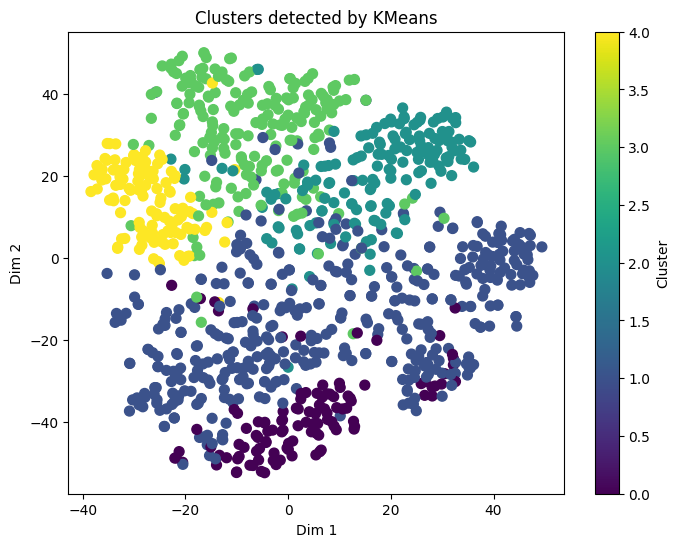

In [57]:
from matplotlib import pyplot as plt
plt.figure(figsize=(8,6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=data["cluster"],
    cmap="viridis",
    s=50
)

plt.title("Clusters detected by KMeans")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.colorbar(label="Cluster")
plt.show()

In [59]:
for i in range(n_clusters):
    print(f"\nCluster {i}:")
    print(data[data["cluster"] == i]["symptoms"].head(10).tolist())


Cluster 0:
["I accidentally left my hand on a hot mug for a minute. It now feels very tender, and there's a small blister.", 'During a birthday party, a hot beverage was knocked onto my back. The area is red, tender, and a small blister is visible on my shoulder.', 'Where my collarbone meets the chest feels puffy by evening and aches when I push up from the floor. Reaching across my body brings a small jab there.', 'I was painting a fence and accidentally sprayed a can of paint on my arm. The area looks like a sunburn.', 'I left a mug too hot on my desk and accidentally touched it. The right wrist feels like it’s on fire and has a blister.', 'Pinching a key between my thumb and index feels weak, like I can’t make a firm circle. Turning a small screw is clumsy though the hand doesn’t feel numb.', 'Reaching overhead repeatedly left a dull ache at the top-back of the shoulder. Lifting the arm to the side feels weak and I avoid heavy objects on that side.', 'Turning a stiff key gives a li

In [60]:
import numpy as np

terms = vectorizer.get_feature_names_out()

for i in range(n_clusters):
    center = kmeans.cluster_centers_[i]
    top_words = [terms[i] for i in center.argsort()[-10:]]
    print(f"Cluster {i}: {top_words}")

Cluster 0: ['forearm', 'makes', 'gives', 'elbow', 'wrist', 'ache', 'reaching', 'feels', 'arm', 'shoulder']
Cluster 1: ['hot', 'deep', 'small', 'like', 'red', 'skin', 'makes', 'sore', 'rash', 'itchy']
Cluster 2: ['headache', 'runny', 'dry', 'day', 'mild', 'cold', 'nose', 'felt', 'throat', 'cough']
Cluster 3: ['tired', 'chest', 'headaches', 'notice', 'blood', 'pressure', 'doctor', 'feeling', 've', 'feel']
Cluster 4: ['sharp', 'like', 'right', 'fever', 'starts', 'throbbing', 'feel', 'head', 'ear', 'pain']
